In [27]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [28]:
import sys
from pathlib import Path

root = next(
    p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists()
)
sys.path.append(str(root / "src"))

from notebook_cache import NotebookCache

# results and prints live on disk, so they survive kernel restarts; one folder per notebook
cache = NotebookCache(root / "cache" / "ddpg_td3_sac")

# Off-policy actor-critic: DDPG → TD3 → SAC

The environment is **Pendulum-v1**, which has a continuous action. Swing a pole up and hold it there.

- obs: `[cos θ, sin θ, θ̇]`
- action: one torque in `[-2, 2]`
- reward: `-(θ² + 0.1·θ̇² + 0.001·u²)`, so 0 is perfect (upright, still, no torque) and about -16 is the worst
- episodes never **terminate**, they only **truncate** at 200 steps


In [29]:
import gymnasium as gym
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

device = "cuda" if torch.cuda.is_available() else "cpu"
env = gym.wrappers.RecordEpisodeStatistics(
    gym.make("Pendulum-v1")
)  # info["episode"]["r"] at episode end
obs_dim = env.observation_space.shape[0]
act_dim = env.action_space.shape[0]
act_high = float(env.action_space.high[0])
print(f"{env.observation_space=}")
print(f"{env.action_space=}")
print(f"{obs_dim=}")
print(f"{act_dim=}")
print(f"{act_high=}")

env.observation_space=Box([-1. -1. -8.], [1. 1. 8.], (3,), float32)
env.action_space=Box(-2.0, 2.0, (1,), float32)
obs_dim=3
act_dim=1
act_high=2.0


In [30]:
scores = []
for _ in range(20):
    env.reset()
    done = False
    while not done:
        _, r, term, trunc, info = env.step(env.action_space.sample())
        done = term or trunc
    scores.append(info["episode"]["r"])
print(f"random baseline: {np.mean(scores):.0f}  (good agents get about -150)")

random baseline: -1183  (good agents get about -150)


## Why a new family?

**PPO is on-policy.** Each batch must come from the current policy, so after a few epochs it gets thrown away. That's stable but wasteful with samples.

**DQN is off-policy.** It keeps old transitions in a replay buffer and reuses each one many times. Its target needs `max_a Q(s', a)`, though. With 2 actions that's a lookup. With a continuous torque there are infinitely many actions, so you can't take the max.

**The fix (DDPG):** learn a second network, the actor `μ(s)`, that _outputs_ the argmax. You train it by gradient ascent on `Q(s, μ(s))`, nudging the action in the direction that makes Q bigger. Then `max_a Q(s', a) ≈ Q(s', μ(s'))`, and we're back to DQN-style learning from a replay buffer.

TD3 and SAC are fixes on top of that same skeleton.


## Step 1: the replay buffer

It stores transitions `(s, a, r, s', T)` and samples random minibatches. Two differences from PPO's batch:

- **No `logp`, no `D`.** Off-policy learning doesn't care which policy collected the data, and there's no GAE sum to stop at episode boundaries. Each transition stands alone.
- **Only `T` matters.** It zeroes the future value in the target `r + γ·(1-T)·Q(s', a')`. Pendulum never terminates, so `T` is always 0 here. A time-limit cut still bootstraps (same lesson as PPO).

It's a fixed-size circular array: once full, the newest transition overwrites the oldest.


In [31]:
class ReplayBuffer:
    def __init__(self, size=100_000):
        self.S = np.zeros((size, obs_dim), np.float32)
        self.A = np.zeros((size, act_dim), np.float32)
        self.R = np.zeros(size, np.float32)
        self.S2 = np.zeros((size, obs_dim), np.float32)
        self.T = np.zeros(size, np.float32)
        self.size, self.i, self.n = size, 0, 0  # i: next slot to write, n: slots filled

    def add(self, s, a, r, s2, term):
        self.S[self.i], self.A[self.i], self.R[self.i] = s, a, r
        self.S2[self.i], self.T[self.i] = s2, term
        self.i = (self.i + 1) % self.size  # wrap around: overwrite the oldest
        self.n = min(self.n + 1, self.size)

    def sample(self, batch_size=256):
        idx = np.random.randint(0, self.n, batch_size)
        f = lambda x: torch.as_tensor(x[idx], device=device)
        return dict(S=f(self.S), A=f(self.A), R=f(self.R), S2=f(self.S2), T=f(self.T))

In [32]:
buf = ReplayBuffer(size=500)  # tiny, to see the wrap-around
s, _ = env.reset(seed=0)
for _ in range(1200):  # 6 episodes, 2.4x the capacity
    a = env.action_space.sample()
    s2, r, term, trunc, _ = env.step(a)
    buf.add(s, a, r, s2, term)
    s = s2 if not (term or trunc) else env.reset()[0]

print("filled:", buf.n, " next write slot:", buf.i)  # 1200 % 500 = 200
b = buf.sample(4)
for k, v in b.items():
    print(f"{k:3s} {tuple(v.shape)}")
print("any terminal?", bool(buf.T.any()))  # Pendulum only truncates

filled: 500  next write slot: 200
S   (4, 3)
A   (4, 1)
R   (4,)
S2  (4, 3)
T   (4,)
any terminal? False


## Step 2: actor and critic

- **Actor** `μ(s)`: state → one action. It's deterministic: no distribution and no sampling, just `tanh` scaled to `[-2, 2]`. Exploration will come from noise added outside the network (Step 3).
- **Critic** `Q(s, a)`: the action is an **input**, concatenated with the state. DQN output one Q per action, which only works when you can list the actions.

This is the core trick: the critic is differentiable in `a`, so `∂Q/∂a` says which way to push the torque to get more value. The actor update is just "move `μ(s)` along `∂Q/∂a`", and backprop through `Q(s, μ(s))` does that for us.


In [33]:
def mlp(inp, out, hidden=256):
    return nn.Sequential(
        nn.Linear(inp, hidden), nn.ReLU(),
        nn.Linear(hidden, hidden),
        nn.ReLU(), nn.Linear(hidden, out),
    ).to(device)


class Actor(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = mlp(obs_dim, act_dim)

    def forward(self, s):
        return act_high * torch.tanh(self.net(s))  # squash into the valid torque range


class Critic(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = mlp(obs_dim + act_dim, 1)  # action goes in, one Q comes out

    def forward(self, s, a):
        return self.net(torch.cat([s, a], -1)).squeeze(-1)

In [34]:
actor, critic = Actor(), Critic()
b = buf.sample(5)
a = actor(b["S"])
print("actions:", a.squeeze(1).tolist())
print("Q(s, a) shape:", tuple(critic(b["S"], a).shape))

# dQ/da: the direction the actor update will push each action
a = a.detach().requires_grad_()
critic(b["S"], a).sum().backward()
print("dQ/da:  ", a.grad.squeeze(1).tolist())

actions: [0.6924193501472473, 0.12393923848867416, 0.2514188289642334, 0.2095516175031662, 0.04288775473833084]
Q(s, a) shape: (5,)
dQ/da:   [-0.04335355758666992, -0.029373157769441605, -0.11032113432884216, -0.017930278554558754, -0.04133046790957451]


## Step 2b: target networks, soft updates

As in DQN, the TD target `r + γ·Q(s', μ(s'))` should come from slow-moving copies (`actor_t`, `critic_t`). Otherwise the label moves every time we fit it.

DQN hard-copied the weights every N steps. DDPG blends a little every step instead (Polyak averaging):

    θ_target ← (1 - τ)·θ_target + τ·θ,   τ = 0.005

The target trails the online net by about `1/τ = 200` updates, smoothly, with no jumps.


In [35]:
import copy


def soft_update(target, net, tau=0.005):
    with torch.no_grad():
        for tp, p in zip(target.parameters(), net.parameters()):
            tp.lerp_(p, tau)  # tp += tau * (p - tp)

In [36]:
critic_t = copy.deepcopy(critic)
with torch.no_grad():  # pretend training moved the online critic
    for p in critic.parameters():
        p.add_(torch.randn_like(p))

dist = lambda: (
    sum(
        (tp - p).pow(2).sum()
        for tp, p in zip(critic_t.parameters(), critic.parameters())
    )
    .sqrt()
    .item()
)
d0 = dist()
soft_update(critic_t, critic)
print(f"gap after 1 update:   {dist() / d0:.4f}  (expect 1 - tau = 0.995)")
for _ in range(199):
    soft_update(critic_t, critic)
print(
    f"gap after 200 updates: {dist() / d0:.4f}  (expect 0.995^200 = {0.995**200:.4f})"
)

gap after 1 update:   0.9950  (expect 1 - tau = 0.995)
gap after 200 updates: 0.3670  (expect 0.995^200 = 0.3670)


## Step 3: the DDPG update

One update on a sampled minibatch has two halves.

**Critic: DQN's regression, with the actor standing in for the max**

    y = r + γ·(1-T)·Q_t(s', μ_t(s'))        (both target nets, no gradient)
    critic_loss = (Q(s, a) - y)²

**Actor: climb the critic**

    actor_loss = -Q(s, μ(s))

The gradient flows through the critic into `μ`. We only step the actor's optimizer, so the critic is just a fixed judge here. (`backward` still leaves gradients on the critic's weights, but `opt_c.zero_grad()` clears them before the next critic step.)

Then both targets get a `soft_update`.

**Exploration:** the actor is deterministic, so `act` adds Gaussian noise (`0.1 × 2 = 0.2` torque std) when collecting data. That's fine off-policy: the buffer can hold data from any policy, noisy or not.


In [37]:
class DDPG:
    def __init__(self, lr=1e-3, gamma=0.99, tau=0.005, expl_noise=0.1):
        self.gamma, self.tau, self.expl_noise = gamma, tau, expl_noise
        self.actor, self.critic = Actor(), Critic()
        self.actor_t, self.critic_t = (
            copy.deepcopy(self.actor),
            copy.deepcopy(self.critic),
        )
        self.opt_a = torch.optim.Adam(self.actor.parameters(), lr=lr)
        self.opt_c = torch.optim.Adam(self.critic.parameters(), lr=lr)

    def act(self, s, explore=True):
        with torch.no_grad():
            a = (
                self.actor(torch.as_tensor(s, dtype=torch.float32, device=device))
                .cpu()
                .numpy()
            )
        if explore:
            a = a + np.random.normal(
                0, self.expl_noise * act_high, act_dim
            )  # the only exploration
        return np.clip(a, -act_high, act_high)

    def update(self, b):
        with torch.no_grad():
            q2 = self.critic_t(
                b["S2"], self.actor_t(b["S2"])
            )  # actor stands in for max_a
            y = b["R"] + self.gamma * (1 - b["T"]) * q2
        q = self.critic(b["S"], b["A"])
        critic_loss = F.mse_loss(q, y)
        self.opt_c.zero_grad()
        critic_loss.backward()
        self.opt_c.step()

        actor_loss = -self.critic(
            b["S"], self.actor(b["S"])
        ).mean()  # push mu(s) up the Q surface
        self.opt_a.zero_grad()
        actor_loss.backward()
        self.opt_a.step()

        soft_update(self.actor_t, self.actor, self.tau)
        soft_update(self.critic_t, self.critic, self.tau)
        return dict(critic_loss=critic_loss.item(), q=q.mean().item())

In [38]:
agent = DDPG()
s, _ = env.reset(seed=0)
print(f"greedy: {agent.act(s, explore=False)[0]:+.3f}")
print("noisy: ", " ".join(f"{agent.act(s)[0]:+.3f}" for _ in range(4)))

# fit on the 500 random transitions already in buf, no new data
torch.manual_seed(0)
np.random.seed(0)
for i in range(1, 1001):
    b = buf.sample(256)
    stats = agent.update(b)
    if i % 200 == 0:
        with torch.no_grad():
            gain = agent.critic(b["S"], agent.actor(b["S"])) - agent.critic(
                b["S"], b["A"]
            )
        print(
            f"update {i:4d}  critic_loss={stats['critic_loss']:7.3f}  Q={stats['q']:7.2f}  "
            f"Q(s,mu(s)) - Q(s,a_random) = {gain.mean():+.2f}"
        )

greedy: +0.036
noisy:  -0.339 +0.025 +0.308 +0.339
update  200  critic_loss=  0.310  Q= -10.02  Q(s,mu(s)) - Q(s,a_random) = +0.37
update  400  critic_loss=  0.102  Q= -14.24  Q(s,mu(s)) - Q(s,a_random) = +0.53
update  600  critic_loss=  0.070  Q= -19.70  Q(s,mu(s)) - Q(s,a_random) = +0.69
update  800  critic_loss=  0.044  Q= -23.98  Q(s,mu(s)) - Q(s,a_random) = +0.75
update 1000  critic_loss=  0.030  Q= -28.05  Q(s,mu(s)) - Q(s,a_random) = +0.82


## Step 4: the training loop

Unlike PPO's collect-batch-then-update, the off-policy loop interleaves: **one env step, then one gradient update**, every step.

- **Warm-up:** the first `start_steps` actions are uniformly random. This fills the buffer with diverse data before the critic means anything, and no updates happen yet.
- `buf.add(..., term)`: only a real termination zeroes the future. A time-limit cut (`trunc`) resets the env but still bootstraps.
- Each update samples a random minibatch from **everything collected so far**, so old transitions keep getting reused. That's where the sample efficiency comes from.

`algo` names the agent class, so TD3 and SAC can plug in later without editing this cell (which would invalidate the cache).


In [39]:
@cache
def train(
    algo="DDPG", total_steps=20_000, start_steps=1_000, batch_size=256, seed=0, **hp
):
    torch.manual_seed(seed)
    np.random.seed(seed)
    env = gym.wrappers.RecordEpisodeStatistics(gym.make("Pendulum-v1"))
    env.action_space.seed(seed)
    agent = globals()[algo](**hp)  # class by name: DDPG now, TD3/SAC later
    buf = ReplayBuffer()

    s, _ = env.reset(seed=seed)
    returns, ends, log, recent = (
        [],
        [],
        [],
        [],
    )  # ends[i]: env step at which episode i finished
    for step in range(1, total_steps + 1):
        a = env.action_space.sample() if step <= start_steps else agent.act(s)
        s2, r, term, trunc, info = env.step(a)
        buf.add(
            s, a, r, s2, term
        )  # trunc still bootstraps: only term zeroes the future
        s = s2
        if term or trunc:
            returns.append(float(info["episode"]["r"]))
            ends.append(step)
            s, _ = env.reset()

        if step > start_steps:
            recent.append(agent.update(buf.sample(batch_size)))
        if step % 2000 == 0 and recent:
            stats = {k: np.mean([st[k] for st in recent]) for k in recent[0]}
            log.append(dict(step=step, **stats))
            recent = []
            print(
                f"steps {step:6d}  episodes {len(returns):3d}  avg10={np.mean(returns[-10:]):7.1f}  "
                + "  ".join(f"{k}={v:.3f}" for k, v in stats.items())
            )

    return dict(agent=agent, returns=returns, ends=ends, log=log)

train: not cached, will compute


In [40]:
res_ddpg = train("DDPG")

steps   2000  episodes  10  avg10=-1343.4  critic_loss=0.654  q=-18.733
steps   4000  episodes  20  avg10= -726.3  critic_loss=0.152  q=-54.604
steps   6000  episodes  30  avg10= -126.6  critic_loss=0.519  q=-65.910
steps   8000  episodes  40  avg10= -122.2  critic_loss=1.058  q=-60.829
steps  10000  episodes  50  avg10= -186.1  critic_loss=1.532  q=-53.568
steps  12000  episodes  60  avg10= -124.2  critic_loss=1.456  q=-45.674
steps  14000  episodes  70  avg10= -166.6  critic_loss=1.328  q=-38.795
steps  16000  episodes  80  avg10= -171.9  critic_loss=1.152  q=-33.793
steps  18000  episodes  90  avg10= -143.8  critic_loss=1.029  q=-30.079
steps  20000  episodes 100  avg10= -205.1  critic_loss=0.978  q=-27.440


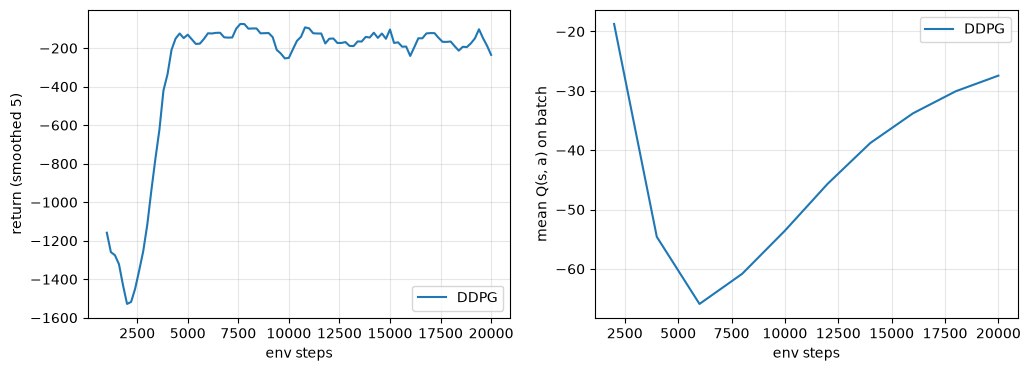

In [41]:
import matplotlib.pyplot as plt


def smooth(xs, k=5):
    return np.convolve(xs, np.ones(k) / k, mode="valid")


def plot_runs(runs, k=5):
    """runs: {label: train() result}. Return vs env steps, and the critic's mean Q."""
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
    for label, res in runs.items():
        ax1.plot(res["ends"][k - 1 :], smooth(res["returns"], k), label=label)
        ax2.plot(
            [l["step"] for l in res["log"]], [l["q"] for l in res["log"]], label=label
        )
    ax1.set_xlabel("env steps")
    ax1.set_ylabel(f"return (smoothed {k})")
    ax2.set_xlabel("env steps")
    ax2.set_ylabel("mean Q(s, a) on batch")
    for ax in (ax1, ax2):
        ax.grid(alpha=0.3)
        ax.legend()
    plt.show()


plot_runs({"DDPG": res_ddpg})

In [42]:
def evaluate(agent, n_episodes=10, seed=100):
    """Greedy (no noise) returns."""
    env = gym.wrappers.RecordEpisodeStatistics(gym.make("Pendulum-v1"))
    scores = []
    for i in range(n_episodes):
        s, _ = env.reset(seed=seed + i)
        done = False
        while not done:
            s, _, term, trunc, info = env.step(agent.act(s, explore=False))
            done = term or trunc
        scores.append(float(info["episode"]["r"]))
    return np.mean(scores), np.std(scores)


m, sd = evaluate(res_ddpg["agent"])
print(f"DDPG greedy: {m:.0f} ± {sd:.0f}   (random: about -1200)")

DDPG greedy: -165 ± 65   (random: about -1200)


In [45]:
vis = gym.make("Pendulum-v1", render_mode="human")
s, _ = vis.reset(seed=0)
total, done = 0.0, False
while not done:
    a = res_ddpg["agent"].act(
        s, explore=False
    )  # greedy; explore=True adds the training noise
    s, r, term, trunc, _ = vis.step(a)
    total += r
    done = term or trunc
vis.close()
print("DDPG episode reward:", total)

DDPG episode reward: -130.11661157026242
